In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv


In [2]:
%pip install -q skorch imbalanced-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 271.6/271.6 kB 9.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
import skorch
import imblearn
print("skorch version:", skorch.__version__)
print("imbalanced-learn version:", imblearn.__version__)


skorch version: 1.4.0
imbalanced-learn version: 0.14.2


In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from imblearn.over_sampling import SMOTE
from skorch import NeuralNetClassifier

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)

Device : cuda


## Chargement & pré-traitement (nettoyage, standardisation)

In [6]:
path = "/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv"
if not os.path.exists(path):
    path = "predictive_maintenance.csv"   
df = pd.read_csv(path)
print(df.shape)
df.head()

(10000, 10)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


# 1. FREATURES
- type : la qualite du produit  3 levels : LOW MEDUIM HIGH
- Air temperature : temp de air ambiant autour de la machine
- Process temperature : temp de la machine pendant usinage
- Rotational speed : vitesse de rotation de outil
- Torque : force de rotation applique
- Tool wear :  usure de outil en min
- Target : une version binaire : 0 = pas de panne, 1 = panne. On la retire de X, parce qu’elle contient déjà « il y a une panne ».
- Failure Type : la vraie cible, avec les 6 classes (No Failure, Heat Dissipation, Power, Overstrain, Tool Wear, Random Failures).

In [7]:
# nettoyage
print("valeurs manquantes :\n", df.isna().sum())
print("doublons :", df.duplicated().sum())

valeurs manquantes :
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64
doublons : 0


In [8]:
print(df.columns.tolist())

['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Target', 'Failure Type']


In [9]:
# Colonnes qu on va pas use 
df = df.drop(columns=["UDI", "Product ID"])

In [10]:
# nommer les colonnes 
df.columns = ["Type", "Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear",
              "Target", "Failure_Type"]

# incoherence existe au niveau du dataset : Target=1 mais Failure_Type = "No Failure"
incoh = df[(df.Target == 1) & (df.Failure_Type == "No Failure")]
print("Lignes incoherentes supprimees :", len(incoh))
df = df.drop(incoh.index)

Lignes incoherentes supprimees : 9


In [11]:
# `Target` (binaire)
df = df.drop(columns=["Target"])
df.Failure_Type.value_counts()

Failure_Type
No Failure                  9643
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64

pour voir lequilibre ou dequilibre

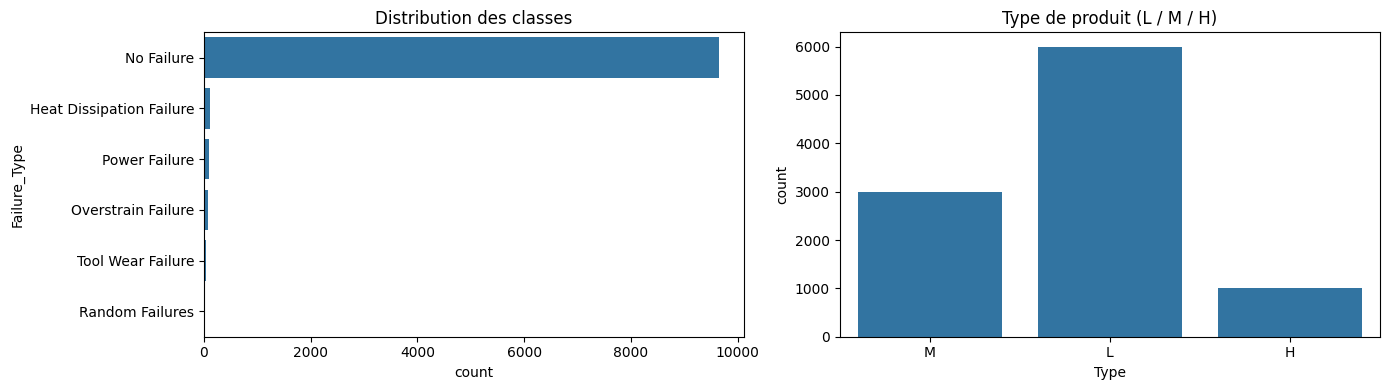

In [12]:
num_cols = ["Air_temp", "Process_temp", "Rot_speed", "Torque", "Tool_wear"]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(y="Failure_Type", data=df, order=df.Failure_Type.value_counts().index, ax=ax[0])
ax[0].set_title("Distribution des classes")
sns.countplot(x="Type", data=df, ax=ax[1])
ax[1].set_title("Type de produit (L / M / H)")
plt.tight_layout(); plt.show()

1. Distribution des classes et des types

Classes. « No Failure » représente 9 643 lignes sur 9 991, soit 96,5 %. Les 4 types de pannes sérieuses font entre 45 et 112 lignes chacun, et « Random Failures » n’a que 18 lignes (0,18 %), ce qui est invisible sur le graphique. C’est la preuve visuelle du déséquilibre : un modèle qui prédirait toujours « No Failure » aurait environ 96,5 % d’accuracy sans rien avoir appris. D’où le SMOTE et le choix du F1 macro.

Type de produit. Il y a environ 6 000 L, 3 000 M et 1 000 H, soit à peu près 60 % / 30 % / 10 %. Les produits de haute qualité sont rares, mais ce déséquilibre est sans gravité, parce que Type est une feature et non la cible.

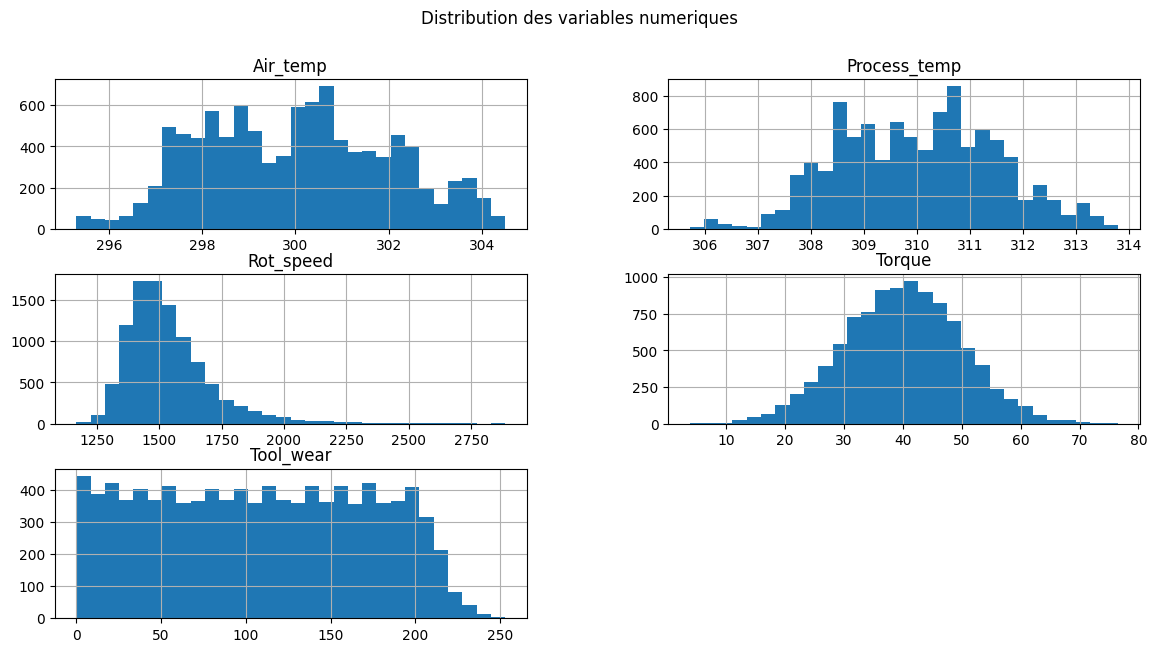

In [13]:
df[num_cols].hist(bins=30, figsize=(14, 7))
plt.suptitle("Distribution des variables numeriques"); plt.show()

2. Distribution des variables numériques
Air_temp (295-304 K) et Process_temp (306-314 K) ont des formes irrégulières à plusieurs bosses, mais sans valeurs aberrantes.
Rot_speed est asymétrique : la plupart des valeurs sont autour de 1 500 rpm, avec une longue queue jusqu’à environ 2 800. Ces valeurs hautes ne sont pas des erreurs, ce sont en partie les pannes de puissance (voir le boxplot).
Torque suit presque une loi normale, centrée sur environ 40 Nm.
Tool_wear est quasi uniforme de 0 à environ 200 min, puis chute nettement après 210.

Conséquence : la standardisation est adaptée. Il ne faut pas supprimer les valeurs extrêmes de Rot_speed, car ce sont justement des cas de panne.

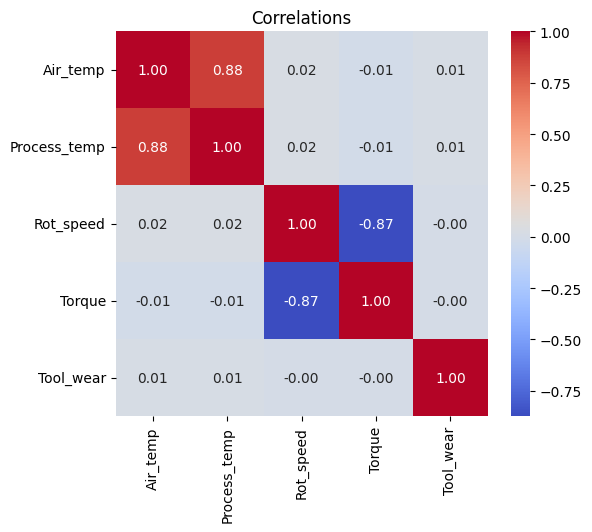

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlations"); plt.show()

3. Matrice de corrélation

Deux paires ressortent :

Air_temp et Process_temp : 0,88. Les deux températures évoluent ensemble.
Rot_speed et Torque : −0,87. Quand la vitesse monte, le couple baisse, comme dans une machine à puissance à peu près constante.

Tool_wear est indépendante de toutes les autres (corrélations ≈ 0). Ces corrélations fortes créent une redondance, mais un MLP s’en accommode. Le point intéressant est que l’information utile n’est pas dans chaque température séparément, mais dans leur écart.

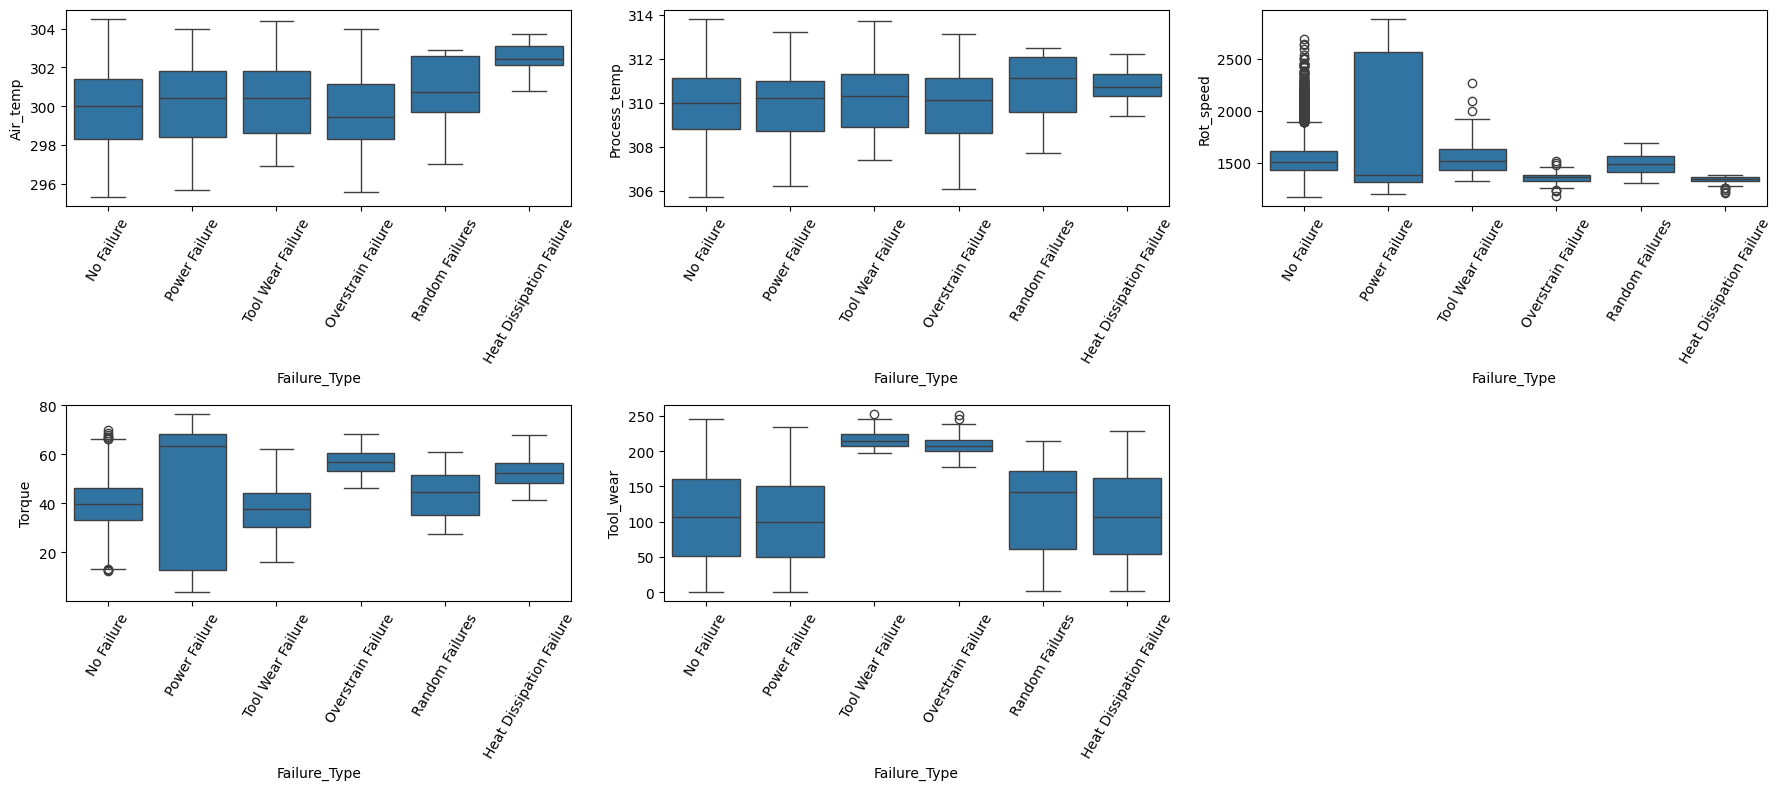

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for a, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x="Failure_Type", y=c, data=df, ax=a)
    a.tick_params(axis="x", rotation=60)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()

## Ce que je lis dans les boxplots : quelles features expliquent quelle panne ?

En regardant les boxplots, j'ai essayé de comprendre ce qui distingue chaque type de panne de « No Failure ».On ramarque aue chaque panne a une signification au niveau du capteur : 

**Heat Dissipation (dissipation de chaleur)**
- Sur `Rot_speed`, la boîte est tout en bas, autour de 1 350 rpm (tours par minute) : la machine tourne lentement.
- Sur `Air_temp`, elle est la plus haute des classes, vers 302,5 K (environ 29,4 °C) : l'air est plutôt chaud.
- En regardant les deux températures ensemble, j'ai remarqué que l'écart `Process_temp − Air_temp` est d'environ 8 K, contre environ 10 K pour une machine saine.
- **Mon interprétation** : une machine lente dans un air chaud, avec un écart de température réduit, évacue mal sa chaleur. Ça colle bien avec le nom de la panne.

**Overstrain (surcharge mécanique)**
- Le couple `Torque` est élevé (~55-60 Nm) : la machine force beaucoup.
- L'usure `Tool_wear` est aussi élevée (~210 min) : l'outil est déjà bien fatigué.
- **Mon interprétation** : une forte contrainte sur un outil déjà usé mène à la surcharge. C'est le couple élevé qui la distingue de Tool Wear.

**Tool Wear (usure de l'outil)**
- `Tool_wear` est très haute (~215 min), mais `Torque` et `Rot_speed` sont au même niveau que « No Failure ».
- **Mon interprétation** : Tool Wear = outil très usé + couple normal. Overstrain = outil très usé + couple très fort. C'est le couple qui permet de les séparer.
  
**Power Failure (panne de puissance)**
- `Rot_speed` (1 200 à 2 800 rpm) et `Torque` (4 à 76 Nm) ont des boîtes très étendues : les valeurs varient énormément.
- **Mon interprétation** : la puissance (couple × vitesse) peut être trop basse ou trop haute, et dans les deux cas la panne survient. C'est pour ça que les valeurs partent dans les deux sens et que les boîtes sont étirées.

**Random Failures (pannes aléatoires)**
- Presque toutes les boîtes chevauchent largement celles de « No Failure ».
- **Mon interprétation** : aucune mesure ne permet de les repérer, ce qui est logique pour des pannes qui arrivent par hasard. Avec seulement 18 lignes, je reste aussi prudente sur ce que montrent ces boîtes.

**Ce que je retiens** : quatre pannes sur cinq ont des signatures claires qu'un réseau de neurones pourra apprendre, alors que Random Failures n'en a aucune. Je m'attends donc à ce que cette dernière soit très difficile à détecter.

## 3. Encodage, split, standardisation, data augmentation (SMOTE)
Le split est fait AVANT la standardisation et le SMOTE pour éviter toute fuite vers le test.
SMOTE crée artificiellement de nouvelles données pour les classes minoritaires.

- Encodage des variables categorielles & cible

In [16]:
df = pd.get_dummies(df, columns=["Type"], dtype=float)
le = LabelEncoder()
y = le.fit_transform(df.Failure_Type)

- Separation features / target

In [17]:
X = df.drop(columns=["Failure_Type"])
class_names = list(le.classes_)
print(dict(enumerate(class_names)))

{0: 'Heat Dissipation Failure', 1: 'No Failure', 2: 'Overstrain Failure', 3: 'Power Failure', 4: 'Random Failures', 5: 'Tool Wear Failure'}


- Split train/test

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

- Standardisation

In [19]:
scaler = StandardScaler()
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
X_train, X_test = X_train.values.astype(np.float32), X_test.values.astype(np.float32) # pour qu il soit compatible avec pytorch

In [21]:
# Data augmentation : SMOTE uniquement sur le train
smote = SMOTE(k_neighbors=3, random_state=SEED)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
X_train_bal = X_train_bal.astype(np.float32)
y_train_bal = y_train_bal.astype(np.int64)

before = pd.Series(y_train).map(dict(enumerate(class_names))).value_counts()
after = pd.Series(y_train_bal).map(dict(enumerate(class_names))).value_counts()
pd.DataFrame({"avant SMOTE": before, "après SMOTE": after})

,avant SMOTE,après SMOTE
Heat Dissipation Failure,90,7714
No Failure,7714,7714
Overstrain Failure,62,7714
Power Failure,76,7714
Random Failures,14,7714
Tool Wear Failure,36,7714


Le jeu d’entraînement était déséquilibré (de 14 à 7 714 exemples par classe). SMOTE a équilibré les 6 classes à 7 714 exemples en générant des exemples synthétiques, uniquement sur le train. La classe « Random Failures », reconstruite à partir de 14 exemples seulement, reste la plus fragile.

## 4. Architecture DNN / MLP

In [22]:
from torch.nn import Module, Linear, ReLU, Softmax
from torch.nn.init import kaiming_uniform_, xavier_uniform_

class MLP(Module):
    def __init__(self, n_inputs, n_classes, h1=64, h2=32):
        super(MLP, self).__init__()
        # entree :  1er hidden layer
        self.hidden1 = Linear(n_inputs, h1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.act1 = ReLU()
        # 2eme hidden layer
        self.hidden2 = Linear(h1, h2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.act2 = ReLU()
        # output layer (6 classes)
        self.hidden3 = Linear(h2, n_classes)
        xavier_uniform_(self.hidden3.weight)
        self.act3 = Softmax(dim=1)

    def forward(self, X):
        X = self.act1(self.hidden1(X))
        X = self.act2(self.hidden2(X))
        X = self.act3(self.hidden3(X)) 
     
        return X

input_dim, n_classes = X_train_bal.shape[1], len(class_names)

In [24]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader


nll = nn.NLLLoss()

def criterion(probs, y):
    return nll(torch.log(probs + 1e-9), y)


def make_loader(X, y, bs, shuffle):
    ds = TensorDataset(torch.tensor(X, dtype=torch.float32),
                       torch.tensor(y, dtype=torch.long))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

def evaluate(model, loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss_sum += criterion(out, yb).item() * len(yb)
            correct += (out.argmax(1) == yb).sum().item()
            n += len(yb)
    return loss_sum / n, correct / n

def fit(model, epochs, lr, opt_cls, weight_decay=0.0, batch_size=128):
    model.to(device)
    opt = opt_cls(model.parameters(), lr=lr, weight_decay=weight_decay)
    tr_loader = make_loader(X_train_bal, y_train_bal, batch_size, True)
    tr_eval = make_loader(X_train_bal, y_train_bal, 1024, False)
    te_eval = make_loader(X_test, y_test, 1024, False)
    hist = {"train_loss": [], "test_loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            opt.step()
        trl, tra = evaluate(model, tr_eval)
        tel, tea = evaluate(model, te_eval)
        for k, v in zip(hist, (trl, tel, tra, tea)):
            hist[k].append(v)
    return hist

La dernière couche utilise `Softmax` pour sortir des probabilités. Comme `CrossEntropyLoss` applique déjà un softmax en interne, l'utiliser ici l'aurait appliqué deux fois. J'utilise donc `NLLLoss` sur le logarithme des probabilités (avec `+ 1e-9` pour éviter log(0)), ce qui revient au même calcul qu'un seul softmax.

In [25]:
torch.manual_seed(SEED)
test_model = MLP(input_dim, n_classes, h1=64, h2=32)
h = fit(test_model, epochs=2, lr=1e-3, opt_cls=torch.optim.Adam)
print(h)

{'train_loss': [0.31461899890811884, 0.19237739658404135], 'test_loss': [0.6976218151115906, 0.5578025568718311], 'train_acc': [0.9002030939417509, 0.9479517759917034], 'test_acc': [0.6848424212106053, 0.7418709354677339]}


## 5. GridSearch (sklearn + skorch)

In [26]:
net = NeuralNetClassifier(
    module=MLP,
    module__n_inputs=input_dim,
    module__n_classes=n_classes,
    criterion=nn.NLLLoss,          #  : NLLLoss
    optimizer=torch.optim.Adam,
    batch_size=128,
    max_epochs=20,
    train_split=None,
    device=device,
    verbose=1,
)

param_grid = {
    "lr": [1e-3, 1e-2],
    "optimizer": [torch.optim.Adam, torch.optim.SGD],
    "max_epochs": [20, 40],
    "module__h1": [64, 128],
    "module__h2": [32, 64],
}

gs = GridSearchCV(net, param_grid, scoring="f1_macro", cv=3, n_jobs=1, verbose=1)
gs.fit(X_train_bal, y_train_bal)

print("Meilleurs hyper-paramètres :", gs.best_params_)
print("F1 macro (CV) :", round(gs.best_score_, 4))
best = gs.best_params_

Fitting 3 folds for each of 32 candidates, totalling 96 fits
  epoch    train_loss     dur
-------  ------------  ------
      1        2.1197  0.5977
      2        1.2182  0.5386
      3        0.9709  0.5454
      4        0.7856  0.5195
      5        0.6619  0.5596
      6        0.5826  0.5678
      7        0.5162  0.5492
      8        0.4876  0.5495
      9        0.4545  0.5266
     10        0.4162  0.5376
     11        0.3847  0.5397
     12        0.3576  0.5492
     13        0.3350  0.5592
     14        0.3169  0.5270
     15        0.3012  0.5462
     16        0.2854  0.5457
     17        0.2725  0.5663
     18        0.2601  0.5908
     19        0.2493  0.5895
     20        0.2382  0.5477
  epoch    train_loss     dur
-------  ------------  ------
      1        1.6847  0.6267
      2        1.0981  0.5549
      3        0.8653  0.5415
      4        0.6940  0.5678
      5        0.6155  0.5655
      6        0.5641  0.5541
      7        0.5205  0.5572
      8  

**Meilleure combinaison** : Adam, lr = 0,001, 40 epochs, réseau 128-64. Adam avec un petit pas (0,001) a battu SGD et le lr de 0,01, qui apprend de façon moins stable.

Les valeurs gagnantes (128/64 neurones, 40 epochs) sont au bord de la grille : un réseau plus grand ou plus d'epochs pourrait faire un peu mieux (piste non testée).

Le F1 macro de 0,944 en validation croisée est **optimiste** : SMOTE a été appliqué avant la validation croisée, donc des points synthétiques issus des exemples d'entraînement se retrouvent dans les folds de validation. Le score de référence est celui du test (F1 macro = 0,53). Une meilleure approche serait d'appliquer SMOTE dans chaque fold, avec un `Pipeline` d'imbalanced-learn.

In [33]:
import matplotlib.pyplot as plt

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["test_loss"], label="test")
    ax[0].set_title(f"Loss / Epochs – {title}"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(hist["train_acc"], label="train"); ax[1].plot(hist["test_acc"], label="test")
    ax[1].set_title(f"Accuracy / Epochs – {title}"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

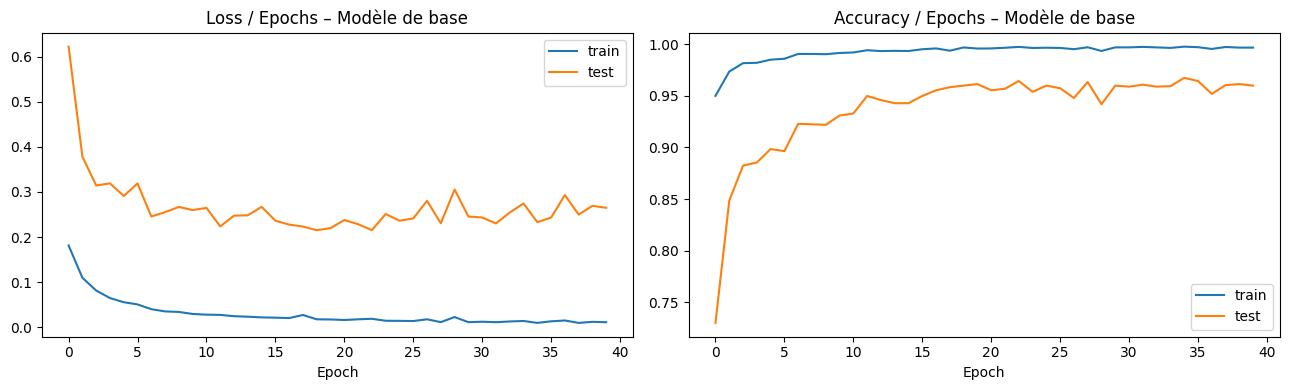

In [30]:
torch.manual_seed(SEED)
model_base = MLP(input_dim, n_classes, h1=best["module__h1"], h2=best["module__h2"])
hist_base = fit(model_base, best["max_epochs"], best["lr"], best["optimizer"])
plot_history(hist_base, "Modèle de base")


interprétation: 
Le modèle converge rapidement : la loss d’entraînement tombe presque à zéro et l’accuracy atteint 99,7 %. Sur le test, la loss diminue jusqu’à environ la 10ᵉ epoch puis stagne en oscillant, et l’accuracy plafonne autour de 95-96 %. L’écart croissant entre train et test indique un début de sur-apprentissage, que l’on cherchera à réduire avec la régularisation. Les oscillations du test s’expliquent par sa petite taille et le très faible nombre d’exemples des classes rares. L’accuracy seule étant peu informative sur un test déséquilibré, on s’appuie aussi sur le F1 macro et la sensibilité par classe.

In [34]:
import pandas as pd
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
import seaborn as sns

def predict(model, X):
    model.eval()
    with torch.no_grad():
        return model(torch.tensor(X, dtype=torch.float32).to(device)).argmax(1).cpu().numpy()

def compute_metrics(model, name):
    rows = {}
    sets = {"train (original)": (X_train, y_train),
            "train (SMOTE)": (X_train_bal, y_train_bal),
            "test": (X_test, y_test)}
    for split, (Xs, ys) in sets.items():
        yp = predict(model, Xs)
        rows[(name, split)] = {
            "accuracy": accuracy_score(ys, yp),
            "precision (macro)": precision_score(ys, yp, average="macro", zero_division=0),
            "sensibilité (macro)": recall_score(ys, yp, average="macro", zero_division=0),
            "F1 (macro)": f1_score(ys, yp, average="macro", zero_division=0),
        }
    return pd.DataFrame(rows).T

res_base = compute_metrics(model_base, "Base")
res_base.round(4)

accuracy  precision (macro)  sensibilité (macro)  \
Base train (original)    0.9819             0.7035               0.9969   
     train (SMOTE)       0.9969             0.9969               0.9969   
     test                0.9600             0.4869               0.5917   

                       F1 (macro)  
Base train (original)      0.7947  
     train (SMOTE)         0.9969  
     test                  0.5298

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.53      0.86      0.66        22
              No Failure       0.99      0.97      0.98      1929
      Overstrain Failure       0.74      0.88      0.80        16
           Power Failure       0.67      0.84      0.74        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.00      0.00      0.00         9

                accuracy                           0.96      1999
               macro avg       0.49      0.59      0.53      1999
            weighted avg       0.97      0.96      0.97      1999



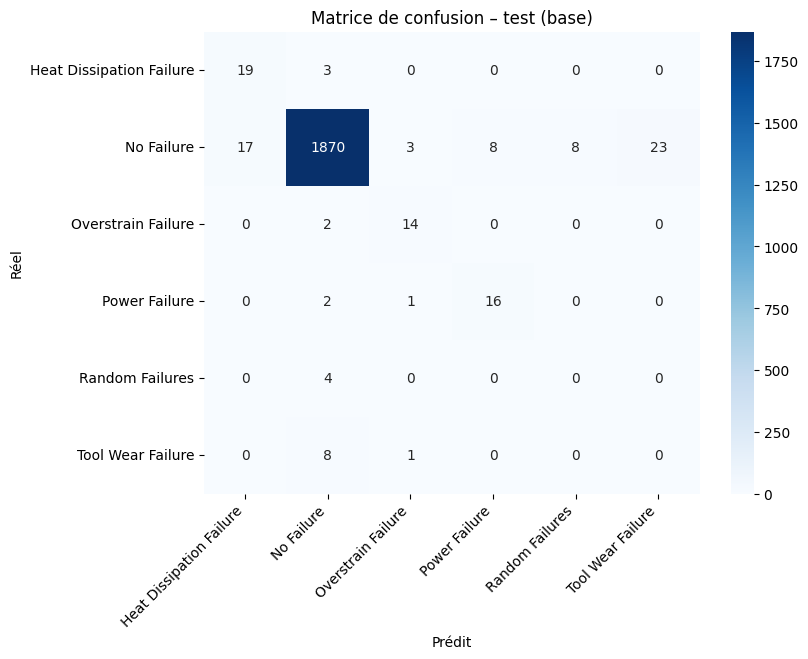

In [35]:
yp = predict(model_base, X_test)
print(classification_report(y_test, yp, target_names=class_names, zero_division=0))
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion – test (base)")
plt.xticks(rotation=45, ha="right"); plt.show()

Le modèle de base détecte bien les pannes de type Heat Dissipation, Overstrain et Power (sensibilité de 84 à 88 %), avec quelques fausses alertes sur des machines saines. En revanche, il échoue sur Tool Wear et Random Failures (F1 = 0), ce qui ramène le F1 macro à 0,53. Les classes rares, reconstruites par SMOTE à partir de très peu d’exemples réels (36 et 14), favorisent la mémorisation et ne généralisent pas. L’accuracy de 96 % est trompeuse, car la classe « No Failure » représente 96,5 % du test.

Limites liées au dataset : Les mauvais résultats sur les classes Tool Wear Failure (F1 = 0) et Random Failures (F1 = 0) s’expliquent surtout par les caractéristiques du dataset, plus que par l’architecture du réseau :

Très peu d’exemples réels : le jeu d’entraînement ne contient que 36 pannes Tool Wear et 14 pannes Random (sur près de 8 000 lignes). SMOTE les complète avec des exemples synthétiques, mais ceux-ci sont de simples variations de quelques cas réels, ce qui favorise la mémorisation plutôt que la généralisation.
Chevauchement avec la classe majoritaire : une usure d’outil élevée caractérise les pannes Tool Wear, mais de nombreuses machines saines ont aussi une usure élevée. Les features seules ne permettent donc pas de bien séparer ces deux classes.
Nature aléatoire de Random Failures : cette panne survient par hasard, indépendamment des mesures des capteurs. Aucune des variables disponibles ne permet de la prédire.
Test très petit pour ces classes : seulement 9 exemples Tool Wear et 4 exemples Random, donc les scores correspondants sont très instables.

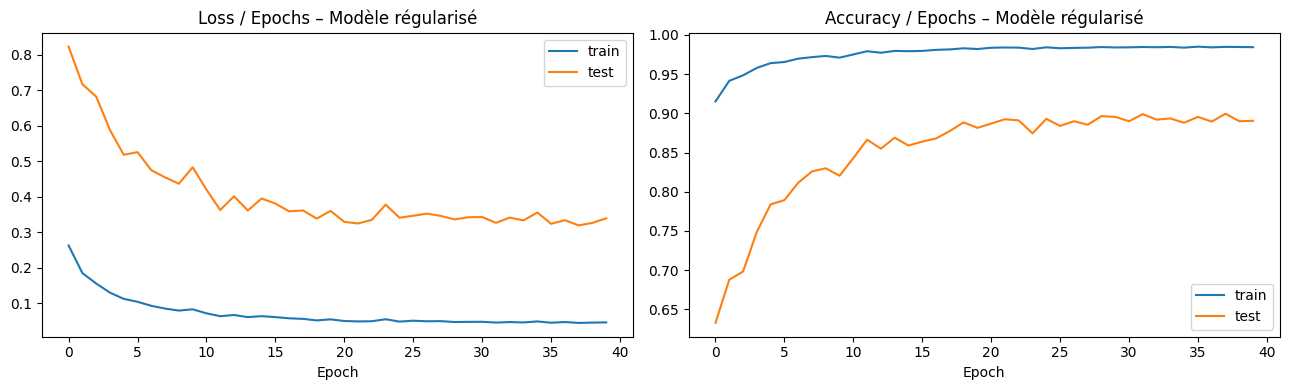

accuracy  precision (macro)  sensibilité (macro)  \
Base       train (original)    0.9819             0.7035               0.9969   
           train (SMOTE)       0.9969             0.9969               0.9969   
           test                0.9600             0.4869               0.5917   
Régularisé train (original)    0.9093             0.4549               0.9843   
           train (SMOTE)       0.9843             0.9848               0.9843   
           test                0.8904             0.3946               0.6597   

                             F1 (macro)  
Base       train (original)      0.7947  
           train (SMOTE)         0.9969  
           test                  0.5298  
Régularisé train (original)      0.5514  
           train (SMOTE)         0.9841  
           test                  0.4662

In [36]:
from torch.nn import Dropout, BatchNorm1d

class MLPReg(Module):
    def __init__(self, n_inputs, n_classes, h1=64, h2=32, dropout=0.3):
        super(MLPReg, self).__init__()
        self.hidden1 = Linear(n_inputs, h1)
        kaiming_uniform_(self.hidden1.weight, nonlinearity='relu')
        self.bn1 = BatchNorm1d(h1)
        self.act1 = ReLU()
        self.drop1 = Dropout(dropout)
        self.hidden2 = Linear(h1, h2)
        kaiming_uniform_(self.hidden2.weight, nonlinearity='relu')
        self.bn2 = BatchNorm1d(h2)
        self.act2 = ReLU()
        self.drop2 = Dropout(dropout)
        self.hidden3 = Linear(h2, n_classes)
        xavier_uniform_(self.hidden3.weight)
        self.act3 = Softmax(dim=1)

    def forward(self, X):
        X = self.drop1(self.act1(self.bn1(self.hidden1(X))))
        X = self.drop2(self.act2(self.bn2(self.hidden2(X))))
        return self.act3(self.hidden3(X))

torch.manual_seed(SEED)
model_reg = MLPReg(input_dim, n_classes, h1=best["module__h1"], h2=best["module__h2"], dropout=0.3)
hist_reg = fit(model_reg, best["max_epochs"], best["lr"], best["optimizer"], weight_decay=1e-4)
plot_history(hist_reg, "Modèle régularisé")

res_reg = compute_metrics(model_reg, "Régularisé")
pd.concat([res_base, res_reg]).round(4)

**Interprétation (modèle régularisé).** Le modèle apprend plus lentement et ses courbes sont plus lisses : la loss de train finit vers 0,05 (contre 0,01 pour le modèle de base) et l'accuracy de train vers 98,5 % (contre 99,7 %), donc la mémorisation du train est réduite. Mais le test n'en profite pas : sa loss se stabilise plus haut (0,33 contre 0,25) et son accuracy tombe à 89 % (contre 96 %).


La régularisation n'améliore pas le F1 macro : elle augmente la sensibilité (plus de pannes détectées) mais crée beaucoup plus de fausses alertes.

                          precision    recall  f1-score   support

Heat Dissipation Failure       0.41      1.00      0.58        22
              No Failure       0.99      0.89      0.94      1929
      Overstrain Failure       0.41      1.00      0.58        16
           Power Failure       0.53      0.84      0.65        19
         Random Failures       0.00      0.00      0.00         4
       Tool Wear Failure       0.02      0.22      0.04         9

                accuracy                           0.89      1999
               macro avg       0.39      0.66      0.47      1999
            weighted avg       0.97      0.89      0.93      1999



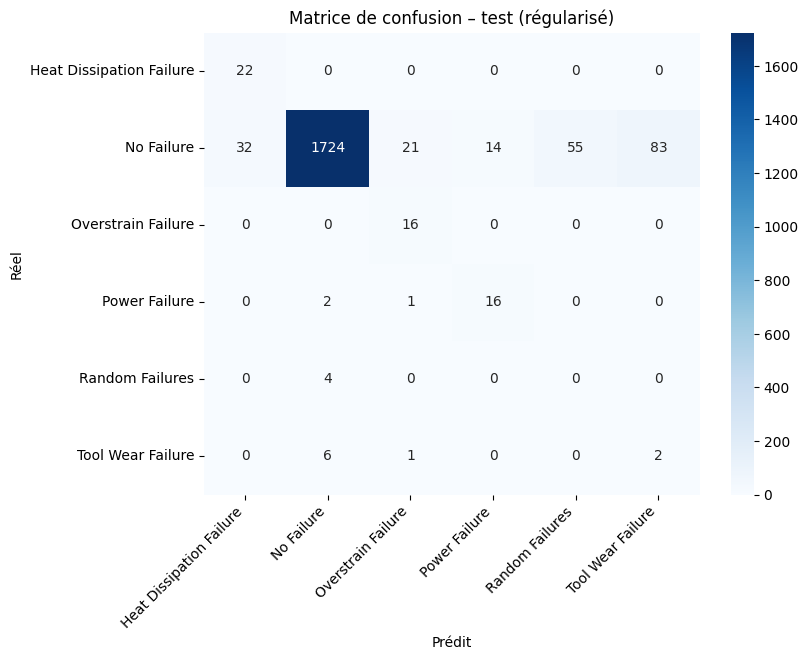

In [37]:
yp_reg = predict(model_reg, X_test)
print(classification_report(y_test, yp_reg, target_names=class_names, zero_division=0))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, yp_reg), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion – test (régularisé)")
plt.xticks(rotation=45, ha="right"); plt.show()

L’analyse par classe montre que la régularisation rend le modèle plus sensible mais moins précis : la sensibilité atteint 100 % pour Heat Dissipation et Overstrain, et 2 pannes Tool Wear sur 9 sont détectées, mais le nombre de fausses alertes sur les machines saines passe de 59 à 205. Pour Tool Wear, la précision n’est que de 2 % (83 fausses alertes pour 2 détections correctes), et Random Failures n’est toujours jamais détectée. Le F1 macro baisse ainsi de 0,53 à 0,47. Le choix du modèle dépend du coût relatif d’une panne manquée par rapport à une fausse alerte : le modèle régularisé convient si l’on privilégie la détection, le modèle de base si l’on privilégie la fiabilité des alertes.

# SYNTHESE
Les classes Tool Wear et Random Failures n’ont pas été détectées correctement, à cause du très faible nombre d’exemples réels et de la nature aléatoire de la seconde. J’en retiens que les performances dépendent autant de la qualité et de la quantité des données que du choix du modèle.
L’accuracy est trompeuse : 96 % pour le modèle de base, alors qu’un modèle répondant toujours « No Failure » aurait 96,5 %. Le F1 macro et la matrice de confusion sont les vrais indicateurs.
Les pannes qui dépendent de combinaisons physiques claires (chaleur, surcharge, puissance) sont bien apprises par le MLP.
Tool Wear et Random Failures sont limitées par le dataset : très peu d’exemples réels, chevauchement de Tool Wear avec la classe saine, nature aléatoire de Random.
Le déséquilibre ne se corrige pas entièrement avec SMOTE : les données synthétiques de classes rares favorisent la mémorisation.
Écart train/test : le modèle de base fait quasiment 100 % sur le train SMOTE mais 53 % de F1 macro sur le test, ce qui montre un sur-apprentissage.
La régularisation ne fait pas mieux globalement : elle déplace le compromis, avec plus de pannes détectées mais beaucoup plus de fausses alertes.
Le choix du modèle dépend de l’usage : le régularisé convient si manquer une panne coûte cher, le modèle de base si les fausses alertes coûtent cher.

# Synthèse de la Partie 2 : ce que j'ai appris

**Bien comprendre les données avant de modéliser.** J'ai commencé par nettoyer le dataset : supprimer les identifiants inutiles, retirer 9 lignes incohérentes (panne annoncée mais « No Failure »), et surtout retirer la colonne `Target`. Elle contient déjà la réponse « il y a une panne ou non », donc la garder aurait été de la triche (une fuite d'information). J'ai aussi compris que le découpage train/test doit venir **avant** la standardisation et SMOTE, sinon le test « voit » des informations du train.

**Lire les graphiques pour comprendre les pannes.** Les boxplots m'ont montré que chaque panne a une « signature » dans les capteurs : machine lente et écart de température réduit pour Heat Dissipation, couple fort et outil usé pour Overstrain, outil très usé seul pour Tool Wear, valeurs extrêmes pour Power. Seule Random Failures n'en a aucune, ce qui est logique puisqu'elle arrive par hasard. J'ai aussi remarqué qu'une mesure seule ne suffit pas toujours : Tool Wear et Overstrain ont tous deux un outil usé, et c'est le couple qui les sépare.

**Le déséquilibre change tout.** Avec 96,5 % de « No Failure », un modèle qui répondrait toujours « pas de panne » aurait 96,5 % d'accuracy sans rien avoir compris. J'ai donc appris à ne pas me fier à l'accuracy et à regarder le F1 macro, la sensibilité et la matrice de confusion. J'ai utilisé SMOTE pour équilibrer le train (7 714 exemples par classe), mais j'ai compris ses limites : la classe Random, par exemple, est passée de 14 exemples réels à 7 714, donc presque tout est synthétique et le modèle risque de la mémoriser.

**Construire et entraîner un réseau en PyTorch.** J'ai aussi découvert un piège technique : combiner `Softmax` dans le modèle avec `CrossEntropyLoss` applique le softmax deux fois. En l'observant, j'ai vu la loss bloquée autour de 1,1 alors que l'accuracy était élevée. Le remplacer par `NLLLoss` sur le log des probabilités a corrigé le problème, et la loss est descendue à 0,19 dès la deuxième epoch.

**Chercher les hyper-paramètres avec un GridSearch.** Avec skorch, j'ai pu utiliser `GridSearchCV` de sklearn sur un modèle PyTorch. La meilleure combinaison était Adam, lr = 0,001, 40 epochs, réseau 128-64, pour un F1 macro de 0,944 en validation croisée. J'ai appris à m'en méfier : SMOTE avait été appliqué avant la validation croisée, donc des points synthétiques proches des exemples d'entraînement se retrouvaient dans la validation, ce qui rend ce score trop optimiste. Le vrai score est celui du test (F1 macro de 0,53).

**Un bon score sur le train ne dit rien.** Le modèle atteint 99,7 % sur le train équilibré par SMOTE, mais seulement 0,53 de F1 macro sur le test. Une partie de l'écart vient du sur-apprentissage, et une autre du fait que le train est équilibré alors que le test ne l'est pas. Ce n'est donc pas une comparaison équitable, et il faut toujours se demander sur quoi on mesure.

**La régularisation n'est pas une solution magique.** J'ai ajouté Dropout, BatchNorm et L2. Le modèle a moins mémorisé le train, et sa sensibilité a augmenté (0,59 → 0,66), mais le nombre de fausses alertes sur les machines saines est passé de 59 à 205 et le F1 macro a baissé (0,53 → 0,47). Il n'y a donc pas de « meilleur » modèle dans l'absolu : si manquer une panne coûte cher, le modèle régularisé se défend, et si les fausses alertes coûtent cher, le modèle de base est meilleur.

**Les limites viennent des données autant que du modèle.** Tool Wear et Random Failures n'ont pas été détectées (F1 = 0 pour le modèle de base). Avec seulement 36 et 14 exemples réels d'entraînement, et 9 et 4 exemples dans le test, leurs scores sont de toute façon très instables. J'en retiens que la qualité et la quantité des données comptent autant que le choix de l'architecture.

**possibilite d ameloiration.** Je pense qu on peut ajouter des variables physiques pour aider le réseau, ou bien utiliser un SMOTE moins agressif , et de plus appliquer SMOTE à l'intérieur de chaque fold de la validation croisée pour obtenir un score moins optimiste.